# How to use `paper_style.py`

Shared plotting style for the PFS TS paper. Please make all paper figures with it, so sizes, fonts and colours match.

**Rules**
1. Call `ps.set_style()` once at the top of your notebook.
2. Make figures with `figsize=ps.figsize("single")` or `ps.figsize("double")`. Don't resize them in LaTeX.
3. Save with `ps.savefig(fig, "name")`. It writes `figures/paper/name.pdf`.
4. Need a change for everyone? Edit `paper_style.py`, not your own notebook.

## 1. Import and set the style

In [8]:
import sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.append("../src")    # path to the folder that contains paper_style.py
import paper_style as ps

ps.set_style()               # ps.set_style(usetex=True) for real LaTeX text (needs LaTeX + cm-super)

## 2. Single-column figure

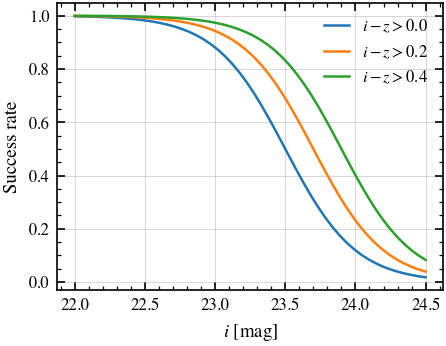

In [9]:
x = np.linspace(22, 24.5, 50)

fig, ax = plt.subplots(figsize=ps.figsize("single"))   # default aspect = 0.75
for dz in [0.0, 0.2, 0.4]:
    ax.plot(x, 1 / (1 + np.exp(4 * (x - 23.5 - dz))), label=rf"$i - z > {dz:.1f}$")
ax.set_xlabel(r"$i$ [mag]")
ax.set_ylabel("Success rate")
ax.legend()
plt.show()

## 3. Colours

Lines use the tab10 colours in order. To pick one by name, use `ps.COLORS`.

['blue', 'orange', 'green', 'red', 'purple', 'brown', 'pink', 'gray', 'olive', 'cyan']


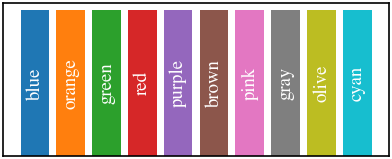

In [10]:
print(list(ps.COLORS))

fig, ax = plt.subplots(figsize=ps.figsize("single", aspect=0.4))
for i, (name, c) in enumerate(ps.COLORS.items()):
    ax.bar(i, 1, color=c)
    ax.text(i, 0.5, name, rotation=90, ha="center", va="center", color="w")
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.show()

Orange/green and blue/purple are hard to tell apart for colour-blind readers. When they must appear together, also change the marker or line style.

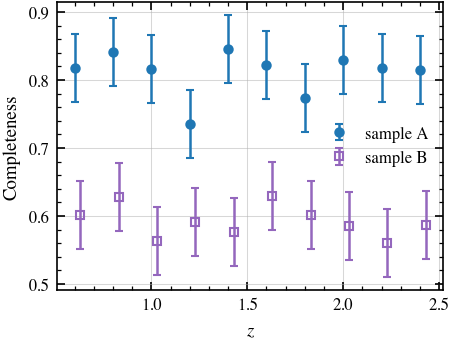

In [11]:
z = np.linspace(0.6, 2.4, 10)
rng = np.random.default_rng(1)

fig, ax = plt.subplots(figsize=ps.figsize("single"))
ax.errorbar(z, 0.8 + 0.05 * rng.normal(size=z.size), yerr=0.05,
            fmt="o", color=ps.COLORS["blue"], label="sample A")
ax.errorbar(z + 0.03, 0.6 + 0.05 * rng.normal(size=z.size), yerr=0.05,
            fmt="s", mfc="none", color=ps.COLORS["purple"], label="sample B")
ax.set_xlabel(r"$z$")
ax.set_ylabel("Completeness")
ax.legend()
plt.show()

## 4. Full-width (double-column) figure with panels

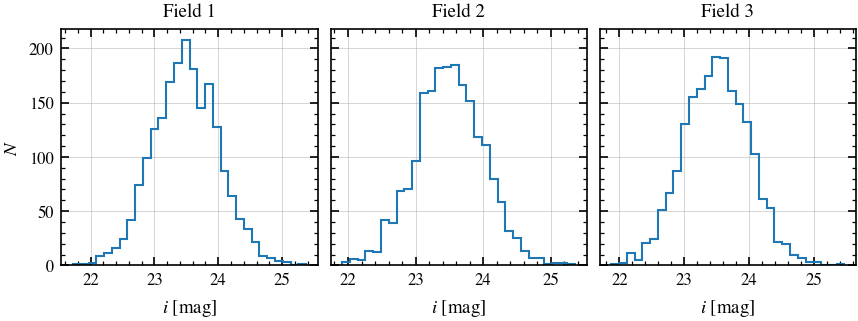

In [12]:
fig, axes = plt.subplots(1, 3, figsize=ps.figsize("double", aspect=0.3), sharey=True)
for ax, title in zip(axes, ["Field 1", "Field 2", "Field 3"]):
    ax.hist(rng.normal(23.5, 0.5, 2000), bins=30, histtype="step")
    ax.set_title(title)
    ax.set_xlabel(r"$i$ [mag]")
axes[0].set_ylabel(r"$N$")
fig.subplots_adjust(wspace=0.05)
plt.show()

## 5. Save for the paper

This writes to `figures/paper/`. Add `formats=("pdf", "png")` if you also want a PNG for slides.

In [13]:
ps.savefig(fig, "example_hist")
print("saved in", ps.FIG_DIR)

saved in /Users/jing/My_Work/Ongoing/PFS_CO_Repo/pfs_co_data/figures/paper


In LaTeX:
```latex
\begin{figure*}
  \includegraphics[width=\textwidth]{figures/paper/example_hist.pdf}
\end{figure*}
```
Use `width=\columnwidth` with `figure` for single-column figures.

## 6. One-off changes

If you need to change a setting for a single figure only, set it on the axes. Don't change `rcParams` in your notebook.

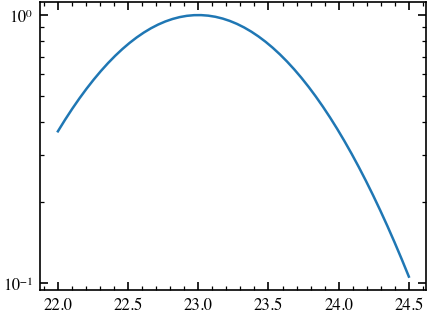

In [14]:
fig, ax = plt.subplots(figsize=ps.figsize("single"))
ax.plot(x, np.exp(-(x - 23) ** 2))
ax.grid(False)          # e.g. turn the grid off for this figure only
ax.set_yscale("log")
plt.show()